# Riesgo en contratos SECOP II - Medellín

La idea del proyecto es ordenar los contratos públicos para saber cuáles revisar primero. No buscamos decir quién es corrupto, sino qué contratos tienen más señales de riesgo según guías de contratación pública.

En este notebook cargamos los contratos, los exploramos, calculamos 5 señales de riesgo para cada uno, sacamos un puntaje y armamos el ranking. Hay que correr las celdas en orden.

## Librerías

In [1]:
import sys
import json
import hashlib
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.0f}".format)

## Datos

Los contratos los bajamos de la API de datos.gov.co (el código está en `src/data/download.py`). Son 2.000 contratos de Medellín de los últimos 2 años, tomados al azar. Guardamos esa descarga en `data/snapshots` para que todos trabajemos con los mismos datos.

El archivo `.meta.json` dice de qué fechas son, cuántos contratos había en total y cómo se tomó la muestra.

In [2]:
ruta_csv = RAIZ / "data" / "snapshots" / "contratos_medellin.csv"
ruta_meta = RAIZ / "data" / "snapshots" / "contratos_medellin.meta.json"

df = pd.read_csv(ruta_csv, low_memory=False)
meta = json.loads(ruta_meta.read_text(encoding="utf-8"))
meta

{'desde': '2024-11-03',
 'hasta': '2026-11-03',
 'contratos_en_ventana': 98763,
 'muestra': 2000,
 'semilla': 42,
 'metodo': 'bloques aleatorios de 5 contratos ordenados por id_contrato',
 'sha256': 'fdc70e8fb8467b29897f7f7bf8c8cf9b3acd7bdd8ea3f722b0057329cca0e7e5',
 'descargado': '2026-11-03T19:57:09'}

El sha256 es como la huella del archivo. Si da True, el CSV es exactamente el que se descargó.

In [3]:
huella = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
huella == meta["sha256"]

True

## Vista general

Cada fila es un contrato. Tenemos la entidad que contrata, la modalidad, el tipo, qué se compra (objeto), el valor, las fechas, los días adicionados y el enlace al proceso en SECOP.

In [4]:
print(df.shape)
df.head()

(2000, 16)


,id_contrato,proceso_de_compra,nombre_entidad,ciudad,estado_contrato,modalidad_de_contratacion,justificacion_modalidad_de,tipo_de_contrato,objeto_del_contrato,fecha_de_firma,fecha_de_fin_del_contrato,valor_del_contrato,dias_adicionados,el_contrato_puede_ser_prorrogado,urlproceso,fecha_de_inicio_del_contrato
0,CO1.PCCNTR.10007502,CO1.BDOS.10935961,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,Medellín,Aprobado,Contratación directa,Servicios profesionales y apoyo a la gestión,Prestación de servicios,PRESTAR LOS SERVICIOS DE APOYO A LA GESTIÓN COMO FORMADOR (A) TÉCNICO 2; DE ...,2026-10-01T20:54:28.982,2026-12-28T23:59:00.000,"10,494,000",0,No,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...,NaN
1,CO1.PCCNTR.10007505,CO1.BDOS.10936208,INSTITUCIÓN UNIVERSITARIA ITM,Medellín,En ejecución,Contratación directa,Servicios profesionales y apoyo a la gestión,Prestación de servicios,Prestación de servicios como contratista independiente; sin vínculo laboral ...,2026-10-02T18:02:12.191,2026-11-25T23:59:00.000,"5,518,232",0,No,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...,2026-10-05T05:00:00.000
2,CO1.PCCNTR.10007513,CO1.BDOS.10936174,INSTITUCIÓN UNIVERSITARIA ITM,Medellín,En ejecución,Contratación directa,Servicios profesionales y apoyo a la gestión,Prestación de servicios,Prestación de servicios como contratista independiente; sin vínculo laboral ...,2026-10-02T19:46:09.752,2026-11-25T23:59:00.000,"5,518,232",0,No,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...,2026-10-05T05:00:00.000
3,CO1.PCCNTR.10007532,CO1.BDOS.10936332,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,Medellín,Aprobado,Contratación directa,Servicios profesionales y apoyo a la gestión,Prestación de servicios,PRESTAR LOS SERVICIOS DE APOYO A LA GESTIÓN COMO FORMADOR (A) TÉCNICO 2; DE ...,2026-10-01T16:48:46.146,2026-12-28T23:59:00.000,"10,494,000",0,No,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...,NaN
4,CO1.PCCNTR.10007536,CO1.BDOS.10936378,INSTITUCIÓN UNIVERSITARIA COLEGIO MAYOR DE ANTIOQUIA,Medellín,En ejecución,Contratación directa,Servicios profesionales y apoyo a la gestión,Prestación de servicios,El contratista de manera autónoma; es decir; sin que exista subordinación de...,2026-10-01T09:27:30.379,2026-10-30T23:59:00.000,"5,355,000",0,No,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...,2026-10-01T09:30:00.000


In [5]:
df.dtypes

id_contrato                             str
proceso_de_compra                       str
nombre_entidad                          str
ciudad                                  str
estado_contrato                         str
modalidad_de_contratacion               str
justificacion_modalidad_de              str
tipo_de_contrato                        str
objeto_del_contrato                     str
fecha_de_firma                          str
fecha_de_fin_del_contrato               str
valor_del_contrato                  float64
dias_adicionados                      int64
el_contrato_puede_ser_prorrogado        str
urlproceso                              str
fecha_de_inicio_del_contrato            str
dtype: object

Pasamos las fechas y los valores a su tipo para poder hacer cuentas con ellos.

In [6]:
for col in ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df["valor_del_contrato"] = pd.to_numeric(df["valor_del_contrato"], errors="coerce")
df["dias_adicionados"] = pd.to_numeric(df["dias_adicionados"], errors="coerce").fillna(0)

df[["fecha_de_firma", "valor_del_contrato", "dias_adicionados"]].describe()

,fecha_de_firma,valor_del_contrato,dias_adicionados
count,2000,"2,000","2,000"
mean,2025-10-11 12:46:31.723884,"189,230,717",9
min,2024-11-05 20:05:44.738000,0,0
25%,2025-03-14 19:36:19.515750,"10,480,500",0
50%,2025-10-07 18:05:19.570000,"21,835,102",0
75%,2026-01-29 20:49:20.192000,"40,747,479",0
max,2026-10-30 09:49:19.215000,"34,010,556,905",259
std,NaN,"1,539,664,351",28


## Exploración

Antes de calcular las señales miramos cómo son los datos.

Modalidad de contratación (en %):

In [7]:
(df["modalidad_de_contratacion"].value_counts(normalize=True) * 100).round(1)

modalidad_de_contratacion
Contratación directa                          87
Contratación régimen especial                  6
Mínima cuantía                                 2
Contratación Directa (con ofertas)             2
Selección abreviada subasta inversa            1
Contratación régimen especial (con ofertas)    0
Concurso de méritos abierto                    0
Licitación pública                             0
Selección Abreviada de Menor Cuantía           0
No Definido                                    0
Licitación pública Obra Publica                0
Name: proportion, dtype: float64

In [8]:
(df["justificacion_modalidad_de"].value_counts(normalize=True) * 100).round(1).head(8)

justificacion_modalidad_de
Servicios profesionales y apoyo a la gestión                                                 84
Regla aplicable                                                                               6
Presupuesto inferior al 10% de la menor cuantía                                               2
Contratos o convenios Interadministrativos (con valor)                                        2
Arrendamiento de inmuebles                                                                    1
Contratos o convenios Interadministrativos (valor cero)                                       1
Suministro de bienes y servicios de características técnicas uniformes y común utilización    1
No existe pluralidad de oferentes en el mercado                                               0
Name: proportion, dtype: float64

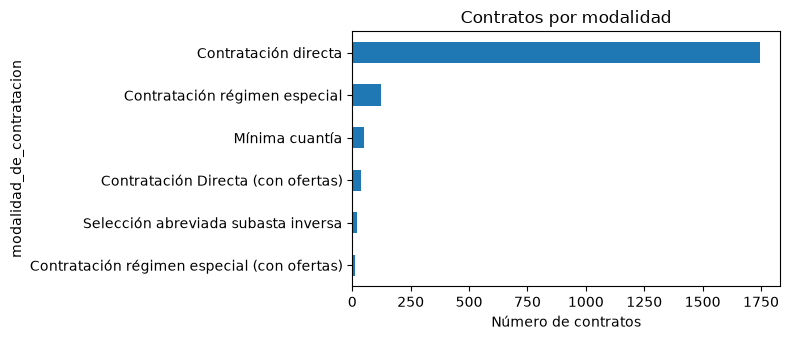

In [9]:
modalidades = df["modalidad_de_contratacion"].value_counts().head(6).sort_values()
modalidades.plot(kind="barh", figsize=(8, 3.5), title="Contratos por modalidad")
plt.xlabel("Número de contratos")
plt.tight_layout()
plt.show()

La mayoría es contratación directa, casi toda por servicios profesionales.

### Entidades

Qué entidades firmaron más contratos en la muestra (en %):

In [10]:
entidades = (df["nombre_entidad"].value_counts(normalize=True) * 100).round(1)
print(df["nombre_entidad"].nunique(), "entidades")
entidades.head(10)

48 entidades


nombre_entidad
INSTITUCIÓN UNIVERSITARIA ITM                                      38
INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN                      9
Institución Universitaria Pascual Bravo COMPRADOR                   7
ICBF REGIONAL ANTIOQUIA                                             4
BIBLIOTECA PUBLICA PILOTO DE MEDELLIN PARA AMERICA LATINA           4
INSTITUCIÓN UNIVERSITARIA COLEGIO MAYOR DE ANTIOQUIA                4
IU PASCUAL BRAVO COMPRADOR                                          3
DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN    3
EMPRESA DE DESARROLLO URBANO DE MEDELLIN                            3
SENA REGIONAL ANTIOQUIA Grupo de Apoyo Administrativo Mixto         3
Name: proportion, dtype: float64

### Valor de los contratos

Hay contratos de pocos millones y otros de miles de millones, por eso el histograma va en escala logarítmica.

In [11]:
df["valor_del_contrato"].describe()

count            2,000
mean       189,230,717
std      1,539,664,351
min                  0
25%         10,480,500
50%         21,835,102
75%         40,747,479
max     34,010,556,905
Name: valor_del_contrato, dtype: float64

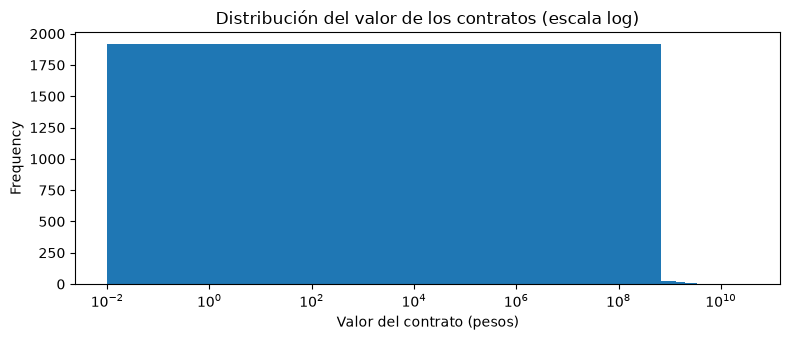

In [12]:
valores = df.loc[df["valor_del_contrato"] > 0, "valor_del_contrato"]
valores.plot(kind="hist", bins=50, logx=True, figsize=(8, 3.5),
             title="Distribución del valor de los contratos (escala log)")
plt.xlabel("Valor del contrato (pesos)")
plt.tight_layout()
plt.show()

### Adiciones

Una adición es cuando le agregan días (o plata) al contrato después de firmado.

In [13]:
con_adiciones = (df["dias_adicionados"] > 0).mean() * 100
print(round(con_adiciones, 1), "% con adiciones")
df.loc[df["dias_adicionados"] > 0, "dias_adicionados"].describe()

20.2 % con adiciones


count   404
mean     45
std      47
min       1
25%      13
50%      30
75%      61
max     259
Name: dias_adicionados, dtype: float64

## Señales de riesgo

Cada señal le pone al contrato una nota de 0, 50 o 100. Las sacamos de guías de contratación pública (OCP, IMCO, RAI SEE y OCDE); el detalle de fuentes y páginas está en `docs/senales.md`. Los umbrales los definimos nosotros porque las guías no los dan para Colombia.

### 1. Contratación directa

Si el contrato se dio sin competencia es más riesgoso. Directa = 100, directa con ofertas o régimen especial = 50, procesos abiertos (licitación, selección abreviada, mínima cuantía) = 0.

In [14]:
def nota_modalidad(modalidad):
    texto = str(modalidad).lower()
    if "directa" in texto:
        return 50 if "con ofertas" in texto else 100
    if "régimen especial" in texto or "regimen especial" in texto or "no definido" in texto:
        return 50
    return 0

df["directa"] = df["modalidad_de_contratacion"].apply(nota_modalidad)
df["directa"].value_counts()

directa
100    1744
50      177
0        79
Name: count, dtype: int64

### 2. Objeto poco claro

Si no se entiende qué se está comprando, es más difícil controlarlo. Por ahora usamos una regla simple: si el objeto tiene menos de 8 palabras se marca. Después esto lo va a hacer un agente (modelo de lenguaje) que lee la frase y dice si es clara o no.

In [15]:
palabras = df["objeto_del_contrato"].fillna("").str.split().str.len()
df["objeto_poco_claro"] = (palabras < 8).map({True: 100, False: 0})
df["objeto_poco_claro"].value_counts()

objeto_poco_claro
0      1998
100       2
Name: count, dtype: int64

Algunos objetos que quedaron marcados:

In [16]:
df.loc[df["objeto_poco_claro"] == 100, "objeto_del_contrato"].head()

92      Gerencia en sistemas de información en salud
1104                       C&S TECNOLOGIA S.A.S. BIC
Name: objeto_del_contrato, dtype: str

### 3. Valor atípico

Comparamos el valor de cada contrato con los de su mismo tipo (no se puede comparar una obra con un arriendo). Si está por encima del percentil 99 de su tipo = 100, por encima del 95 = 50. Si el tipo tiene menos de 30 contratos no lo comparamos.

In [17]:
percentil = df.groupby("tipo_de_contrato")["valor_del_contrato"].rank(pct=True)
tamano_grupo = df.groupby("tipo_de_contrato")["valor_del_contrato"].transform("size")

df["valor_atipico"] = 0
df.loc[percentil >= 0.95, "valor_atipico"] = 50
df.loc[percentil >= 0.99, "valor_atipico"] = 100
df.loc[(tamano_grupo < 30) | (df["valor_del_contrato"].fillna(0) <= 0), "valor_atipico"] = 0

df["valor_atipico"].value_counts()

valor_atipico
0      1904
50       76
100      20
Name: count, dtype: int64

### 4. Adiciones

Comparamos los días adicionados con la duración del contrato. Sin adiciones = 0, menos del 30 % de la duración = 50, 30 % o más = 100.

In [18]:
duracion = (df["fecha_de_fin_del_contrato"] - df["fecha_de_inicio_del_contrato"]).dt.days
proporcion = df["dias_adicionados"] / duracion.where(duracion > 0)

df["adiciones"] = 0
df.loc[df["dias_adicionados"] > 0, "adiciones"] = 50
df.loc[(df["dias_adicionados"] > 0) & (proporcion >= 0.30), "adiciones"] = 100

df["adiciones"].value_counts()

adiciones
0      1596
50      275
100     129
Name: count, dtype: int64

### 5. Sin enlace al proceso

Si el contrato no tiene enlace al proceso en SECOP no se puede revisar, entonces se marca con 100.

In [19]:
vacio = df["urlproceso"].isna() | (df["urlproceso"].astype(str).str.strip() == "")
df["sin_enlace"] = vacio.map({True: 100, False: 0})
df["sin_enlace"].value_counts()

sin_enlace
0    2000
Name: count, dtype: int64

### Cuántos contratos marca cada señal

In [20]:
SENALES = ["directa", "objeto_poco_claro", "valor_atipico", "adiciones", "sin_enlace"]
resumen = pd.DataFrame({
    "contratos marcados": (df[SENALES] > 0).sum(),
    "% de la muestra": ((df[SENALES] > 0).mean() * 100).round(1),
})
resumen

,contratos marcados,% de la muestra
directa,1921,96
objeto_poco_claro,2,0
valor_atipico,96,5
adiciones,404,20
sin_enlace,0,0


Una señal sirve cuando marca a algunos contratos y a otros no. Directa marca casi todos y sin enlace no marca ninguno, así que esas dos ayudan poco a ordenar. Las que más diferencian son valor y adiciones.

## Puntaje

El puntaje es el promedio de las 5 notas, va de 0 a 100. Por ejemplo, un contrato con notas 100, 0, 50, 100 y 0 queda con 50.

In [21]:
df["puntaje"] = df[SENALES].mean(axis=1)
df["puntaje"].value_counts().sort_index()

puntaje
0       58
10     120
20    1394
30     315
40     104
50       5
60       4
Name: count, dtype: int64

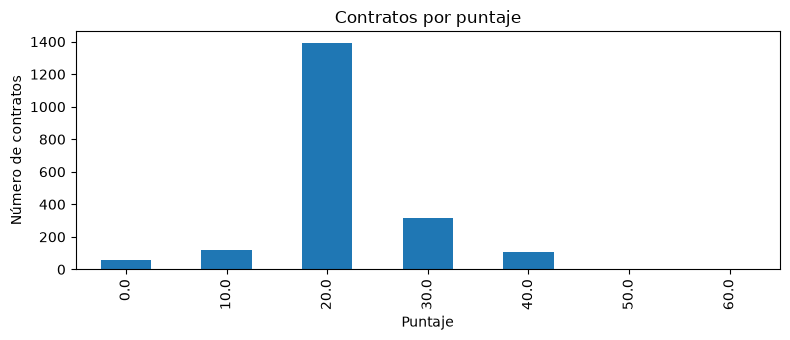

In [22]:
df["puntaje"].value_counts().sort_index().plot(kind="bar", figsize=(8, 3.5),
                                                title="Contratos por puntaje")
plt.xlabel("Puntaje")
plt.ylabel("Número de contratos")
plt.tight_layout()
plt.show()

## Ranking

Ordenamos de mayor a menor puntaje. Si dos contratos empatan, va primero el de mayor valor (hay más plata en juego). Después ponemos la alerta según la posición: el primer 10 % es alta, el siguiente 20 % media y el resto baja. Un contrato con puntaje 0 siempre queda en baja.

In [23]:
ranking = df.sort_values(["puntaje", "valor_del_contrato"], ascending=[False, False]).reset_index(drop=True)

n = len(ranking)
posicion = pd.Series(range(n))
ranking["alerta"] = "baja"
ranking.loc[(posicion < int(n * 0.30 + 0.999)) & (ranking["puntaje"] > 0), "alerta"] = "media"
ranking.loc[(posicion < int(n * 0.10 + 0.999)) & (ranking["puntaje"] > 0), "alerta"] = "alta"

ranking["alerta"].value_counts()

alerta
baja     1400
media     400
alta      200
Name: count, dtype: int64

Los 10 contratos de arriba del ranking:

In [24]:
columnas = ["nombre_entidad", "tipo_de_contrato", "objeto_del_contrato",
            "valor_del_contrato", "dias_adicionados", "puntaje", "alerta"] + SENALES
ranking[columnas].head(10)

,nombre_entidad,tipo_de_contrato,objeto_del_contrato,valor_del_contrato,dias_adicionados,puntaje,alerta,directa,objeto_poco_claro,valor_atipico,adiciones,sin_enlace
0,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN,Prestación de servicios,Prestar servicios para brindar atención básica y diferencial de la población...,"7,012,967,474",10,60,alta,100,0,100,100,0
1,DEPARTAMENTO DE ANTIOQUIA//,Prestación de servicios,BRINDAR SERVICIO DE CONECTIVIDAD A INTERNET DE CALIDAD; SOPORTE TÉCNICO; RED...,"2,745,380,574",214,60,alta,100,0,100,100,0
2,IU. Digital,Prestación de servicios,Contrato Interadministrativo de Administración delegada de los recursos entr...,"2,591,862,685",152,60,alta,100,0,100,100,0
3,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN,Prestación de servicios,PRESTACIÓN DE SERVICIOS DE APOYO A LA GESTIÓN AL CENTRO DE CAPACITACIÓN; FOR...,"1,199,518,168",181,60,alta,100,0,100,100,0
4,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN,Prestación de servicios,Prestar servicios para el apoyo al fortalecimiento; operación y desarrollo d...,"12,979,842,931",34,50,alta,100,0,100,50,0
5,DEPARTAMENTO DE ANTIOQUIA//,Prestación de servicios,APOYO A LA GESTIÓN DE LOS INGRESOS DEL DEPARTAMENTO DE ANTIOQUIA; COMO ESTRA...,"7,786,588,142",36,50,alta,100,0,100,50,0
6,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN,Prestación de servicios,Prestación de Servicios para el fortalecimiento de la atención en los Jardin...,"5,636,339,108",32,50,alta,100,0,100,50,0
7,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN,Prestación de servicios,PRESTAR SERVICIOS PROFESIONALES PARA FORTALECER LAS ESTRATEGIAS DE PREVENCIÓ...,"690,118,084",6,50,alta,100,0,100,50,0
8,Universidad Pontificia Bolivariana,Prestación de servicios,Gerencia en sistemas de información en salud,"36,000,000",123,50,alta,50,100,0,100,0
9,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN,Otro,CONTRATO INTERADMINISTRATIVO PARA DESARROLLAR ESTRATEGIAS DE GESTIÓN DEL CON...,"32,701,792,313",193,40,alta,50,0,50,100,0


Ojo: alerta alta no quiere decir que el contrato tenga algo malo, solo que tiene más señales y conviene revisarlo primero. Eso es lo que vamos a comprobar con la revisión manual.

## Comprobación

Todo lo que hicimos aquí también está en el código de `src/`, que es el que corre el proyecto. Si da True, el notebook y el código dan exactamente el mismo resultado.

In [25]:
from src.build_ranking import construir

ranking_src = construir(str(ruta_csv))
mismas = ["id_contrato", "puntaje", "alerta"] + SENALES
ranking[mismas].reset_index(drop=True).equals(ranking_src[mismas].reset_index(drop=True))

True

## Lo que falta

- El agente para la señal 2 (objeto poco claro).
- La revisión manual de 30 contratos, a ciegas (`data/review/hoja_revision.csv`).
- Mejorar las señales de directa y sin enlace.
- El tablero con el ranking.